# Fase 3: Evaluación sin Odds como Features

**Tesis:** Modelo Predictivo de Resultados — Premier League 2017–2025  
**Objetivo de este notebook:** Evaluar si el modelo tiene valor predictivo real sin información del mercado  
**Input:** `model_dataset_selected.csv` (generado en 03_feature_selection.ipynb)  
**Output:** Comparativa con/without odds

---

## ¿Qué son las Odds de Apuestas?

Las **odds** (cuotas) representan las probabilidades implícitas del mercado de apuestas:

- **odds_home**: Cuota para victoria del local
- **odds_draw**: Cuota para empate
- **odds_away**: Cuota para victoria del visitante

De las odds se derivan probabilidades implícitas:

```python
probabilidad = 1 / odds
```

### ¿Por qué importan?

Las odds encapsulan **toda la información del mercado**:
- Forma de los equipos
- Lesiones de jugadores
- Condiciones del partido
- Opinión de expertos

El mercado de apuestas es **muy difícil de superar** — incluso los mejores modelos apenas logran +2-3 puntos de accuracy sobre las odds.

## Pregunta Clave de este Notebook

**¿Nuestro modelo tiene valor predictivo REAL o solo "copia" al mercado?**

Para responderlo, compararemos:
- **Configuración A**: Con odds (baseline)
- **Configuración B**: Sin odds

Si el modelo **pierde mucho rendimiento** sin odds → depende del mercado
Si el modelo **mantiene rendimiento** → tiene valor predictivo real

---
## 1. Carga de Datos y Configuración

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score, brier_score_loss

# Utilidades personalizadas
import sys
sys.path.insert(0, '.')
from utils.split_utils import expanding_window_split, print_fold_summary
from utils.evaluation_utils import evaluate_model

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

TARGET = 'target_home_win'

print('Librerías cargadas exitosamente.')

Librerías cargadas exitosamente.


In [2]:
import sys
sys.path.insert(0, '.')
from utils.evaluation_utils import leer_baseline
BASELINE_ACC = leer_baseline()   # accuracy del mercado, calculada en 01_eda.ipynb


In [3]:
# Cargar dataset
df_full = pd.read_csv('Dataset/model_dataset_selected.csv')

print(f' Dataset cargado:')
print(f'   Filas: {df_full.shape[0]:,}')
print(f'   Features: {df_full.shape[1] - 1}')

# Identificar features de odds
odds_features = [col for col in df_full.columns 
                 if any(p in col for p in ['odds_', 'market_'])]

print(f'\n Features de odds/mercado ({len(odds_features)}):')
for f in odds_features:
    print(f'   - {f}')

 Dataset cargado:
   Filas: 2,973
   Features: 29

 Features de odds/mercado (3):
   - odds_home_prob
   - market_form_diff
   - market_uncertainty


---
## 2. Definir Configuraciones

### ¿Qué hacemos?

Creamos dos versiones del dataset:
- **Con odds**: Todas las features (baseline)
- **Sin odds**: Eliminamos features de mercado

In [4]:
# Configuración A: Con odds (baseline)
X_with_odds = df_full.drop(columns=[TARGET, 'season'])
y = df_full[TARGET]

# Configuración B: Sin odds
X_without_odds = df_full.drop(columns=[TARGET, 'season'] + odds_features)

print(' CONFIGURACIONES DEFINIDAS:')
print('='*60)
print(f'\n Configuración A (Con odds):')
print(f'   Features: {X_with_odds.shape[1]}')
print(f'   Incluye: {odds_features}')
print(f'\n Configuración B (Sin odds):')
print(f'   Features: {X_without_odds.shape[1]}')
print(f'   Eliminadas: {len(odds_features)} features de mercado')
print(f'\n Diferencia: {X_with_odds.shape[1] - X_without_odds.shape[1]} features')

 CONFIGURACIONES DEFINIDAS:

 Configuración A (Con odds):
   Features: 28
   Incluye: ['odds_home_prob', 'market_form_diff', 'market_uncertainty']

 Configuración B (Sin odds):
   Features: 25
   Eliminadas: 3 features de mercado

 Diferencia: 3 features


---
## 3. Modelos a Evaluar

Usaremos los **mejores hiperparámetros** encontrados en el notebook anterior.

In [5]:
# Modelos con mejores hiperparámetros (del tuning anterior)
models = {
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=400, learning_rate=0.05, max_depth=4,
        subsample=0.8, random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=400, max_depth=12, min_samples_leaf=4,
        random_state=42, n_jobs=-1, class_weight='balanced'
    ),
    'Logistic Regression': LogisticRegression(
        max_iter=1000, C=1.0, random_state=42, class_weight='balanced'
    ),
    'SVM (RBF)': SVC(
        kernel='rbf', C=1.0, gamma='scale', probability=True,
        random_state=42, class_weight='balanced'
    ),
    'MLP': MLPClassifier(
        hidden_layer_sizes=(256, 128, 64), alpha=1e-3,
        max_iter=500, random_state=42, early_stopping=True
    ),
}

# Modelos que necesitan escalado
needs_scaling = ['Logistic Regression', 'SVM (RBF)', 'MLP']

print(' Modelos configurados:')
for name in models.keys():
    print(f'   - {name}')

 Modelos configurados:
   - Gradient Boosting
   - Random Forest
   - Logistic Regression
   - SVM (RBF)
   - MLP


---
## 4. Evaluación con Expanding Window

### ¿Por qué usar expanding window?

Para una comparación justa, debemos evaluar ambos modelos (con y sin odds) en los **mismos folds** y con los **mismos splits temporales**.

In [6]:
# Generar folds
folds = expanding_window_split(df_full, min_train_seasons=1)

# Almacenar resultados
results_with_odds = []
results_without_odds = []

print(' EVALUACIÓN CON vs SIN ODDS')
print('='*70)
print(f' Folds: {len(folds)}')
print(f' Modelos: {len(models)}')
print('='*70)

total_start = time.time()

for fold_idx, (train_idx, test_idx, train_s, test_s) in enumerate(folds):
    fold_start = time.time()
    
    print(f'\n--- FOLD {fold_idx + 1}/{len(folds)} ---')
    print(f'   Train: {train_s} ({len(train_idx)} partidos)')
    print(f'   Test:  {test_s} ({len(test_idx)} partidos)')
    
    for model_name, model in models.items():
        # --- Configuración A: Con odds ---
        X_train_w = X_with_odds.iloc[train_idx]
        X_test_w = X_with_odds.iloc[test_idx]
        
        # --- Configuración B: Sin odds ---
        X_train_wo = X_without_odds.iloc[train_idx]
        X_test_wo = X_without_odds.iloc[test_idx]
        
        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]
        
        # Escalar si es necesario
        if model_name in needs_scaling:
            scaler_w = StandardScaler()
            X_train_w = scaler_w.fit_transform(X_train_w)
            X_test_w = scaler_w.transform(X_test_w)
            
            scaler_wo = StandardScaler()
            X_train_wo = scaler_wo.fit_transform(X_train_wo)
            X_test_wo = scaler_wo.transform(X_test_wo)
        else:
            X_train_w = X_train_w.values
            X_test_w = X_test_w.values
            X_train_wo = X_train_wo.values
            X_test_wo = X_test_wo.values
        
        # --- Entrenar y evaluar: Con odds ---
        from sklearn.base import clone
        model_w = clone(model)
        model_w.fit(X_train_w, y_train)
        y_pred_w = model_w.predict(X_test_w)
        y_proba_w = model_w.predict_proba(X_test_w)[:, 1]
        
        metrics_w = evaluate_model(y_test, y_pred_w, y_proba_w, model_name)
        metrics_w['fold'] = fold_idx + 1
        metrics_w['config'] = 'Con odds'
        metrics_w['train_seasons'] = str(train_s)
        metrics_w['test_season'] = str(test_s)
        results_with_odds.append(metrics_w)
        
        # --- Entrenar y evaluar: Sin odds ---
        model_wo = clone(model)
        model_wo.fit(X_train_wo, y_train)
        y_pred_wo = model_wo.predict(X_test_wo)
        y_proba_wo = model_wo.predict_proba(X_test_wo)[:, 1]
        
        metrics_wo = evaluate_model(y_test, y_pred_wo, y_proba_wo, model_name)
        metrics_wo['fold'] = fold_idx + 1
        metrics_wo['config'] = 'Sin odds'
        metrics_wo['train_seasons'] = str(train_s)
        metrics_wo['test_season'] = str(test_s)
        results_without_odds.append(metrics_wo)
    
    fold_time = time.time() - fold_start
    print(f'   Fold completado en {fold_time:.1f}s')

total_time = time.time() - total_start
print(f'\n{"="*70}')
print(f' EVALUACIÓN COMPLETADA — Tiempo total: {total_time/60:.1f} minutos')
print(f'{"="*70}')

 EVALUACIÓN CON vs SIN ODDS
 Folds: 7
 Modelos: 5

--- FOLD 1/7 ---
   Train: ['2017-2018'] (347 partidos)
   Test:  2018-2019 (371 partidos)


   Fold completado en 3.1s

--- FOLD 2/7 ---
   Train: ['2017-2018', '2018-2019'] (718 partidos)
   Test:  2019-2020 (371 partidos)


   Fold completado en 4.5s

--- FOLD 3/7 ---
   Train: ['2017-2018', '2018-2019', '2019-2020'] (1089 partidos)
   Test:  2020-2021 (377 partidos)


   Fold completado en 5.9s

--- FOLD 4/7 ---
   Train: ['2017-2018', '2018-2019', '2019-2020', '2020-2021'] (1466 partidos)
   Test:  2021-2022 (377 partidos)


   Fold completado en 7.3s

--- FOLD 5/7 ---
   Train: ['2017-2018', '2018-2019', '2019-2020', '2020-2021', '2021-2022'] (1843 partidos)
   Test:  2022-2023 (377 partidos)


   Fold completado en 9.2s

--- FOLD 6/7 ---
   Train: ['2017-2018', '2018-2019', '2019-2020', '2020-2021', '2021-2022', '2022-2023'] (2220 partidos)
   Test:  2023-2024 (376 partidos)


   Fold completado en 10.9s

--- FOLD 7/7 ---
   Train: ['2017-2018', '2018-2019', '2019-2020', '2020-2021', '2021-2022', '2022-2023', '2023-2024'] (2596 partidos)
   Test:  2024-2025 (377 partidos)


   Fold completado en 12.6s

 EVALUACIÓN COMPLETADA — Tiempo total: 0.9 minutos


---
## 5. Análisis de Resultados

### ¿Qué buscamos?

1. **Diferencia de rendimiento**: ¿Cuánto pierde el modelo sin odds?
2. **Consistencia**: ¿Todos los modelos pierden igual?
3. **Significancia**: ¿La diferencia es estadísticamente significativa?

In [7]:
# Crear DataFrames
df_with = pd.DataFrame(results_with_odds)
df_without = pd.DataFrame(results_without_odds)

# Calcular promedios por modelo
summary_with = df_with.groupby('model').agg({
    'accuracy': ['mean', 'std'],
    'f1_score': ['mean', 'std'],
    'roc_auc': ['mean', 'std'],
    'brier_score': ['mean', 'std']
}).round(4)
summary_with.columns = [f'{col[0]}_{col[1]}' for col in summary_with.columns]

summary_without = df_without.groupby('model').agg({
    'accuracy': ['mean', 'std'],
    'f1_score': ['mean', 'std'],
    'roc_auc': ['mean', 'std'],
    'brier_score': ['mean', 'std']
}).round(4)
summary_without.columns = [f'{col[0]}_{col[1]}' for col in summary_without.columns]

print(' RESULTADOS — CON ODDS')
print('='*60)
print(summary_with.to_string())

print('\n\n RESULTADOS — SIN ODDS')
print('='*60)
print(summary_without.to_string())

 RESULTADOS — CON ODDS
                     accuracy_mean  accuracy_std  f1_score_mean  f1_score_std  roc_auc_mean  roc_auc_std  brier_score_mean  brier_score_std
model                                                                                                                                      
Gradient Boosting           0.6442        0.0274         0.5801        0.0282        0.6903       0.0306            0.2382           0.0203
Logistic Regression         0.6721        0.0209         0.6431        0.0286        0.7255       0.0307            0.2144           0.0132
MLP                         0.6629        0.0272         0.5831        0.0597        0.7129       0.0344            0.2179           0.0149
Random Forest               0.6831        0.0121         0.6273        0.0243        0.7218       0.0212            0.2117           0.0069
SVM (RBF)                   0.6429        0.0758         0.6199        0.0229        0.6959       0.0311            0.2218           0.01

### Tabla Comparativa: Caída de Rendimiento

In [8]:
# Calcular diferencia
comparison = pd.DataFrame(index=summary_with.index)

for metric in ['accuracy', 'f1_score', 'roc_auc', 'brier_score']:
    comparison[f'{metric}_con'] = summary_with[f'{metric}_mean']
    comparison[f'{metric}_sin'] = summary_without[f'{metric}_mean']
    comparison[f'{metric}_diff'] = summary_with[f'{metric}_mean'] - summary_without[f'{metric}_mean']
    comparison[f'{metric}_pct'] = (comparison[f'{metric}_diff'] / summary_with[f'{metric}_mean'] * 100).round(2)

print(' COMPARACIÓN: CAÍDA DE RENDIMIENTO SIN ODDS')
print('='*70)
print('\n Accuracy:')
for model in comparison.index:
    row = comparison.loc[model]
    print(f'   {model:<25} {row["accuracy_con"]:.4f} → {row["accuracy_sin"]:.4f} '
          f'(Δ = {row["accuracy_diff"]:+.4f}, {row["accuracy_pct"]:+.2f}%)')

print('\n F1-Score:')
for model in comparison.index:
    row = comparison.loc[model]
    print(f'   {model:<25} {row["f1_score_con"]:.4f} → {row["f1_score_sin"]:.4f} '
          f'(Δ = {row["f1_score_diff"]:+.4f}, {row["f1_score_pct"]:+.2f}%)')

print('\n ROC-AUC:')
for model in comparison.index:
    row = comparison.loc[model]
    print(f'   {model:<25} {row["roc_auc_con"]:.4f} → {row["roc_auc_sin"]:.4f} '
          f'(Δ = {row["roc_auc_diff"]:+.4f}, {row["roc_auc_pct"]:+.2f}%)')

 COMPARACIÓN: CAÍDA DE RENDIMIENTO SIN ODDS

 Accuracy:
   Gradient Boosting         0.6442 → 0.6267 (Δ = +0.0175, +2.72%)
   Logistic Regression       0.6721 → 0.6480 (Δ = +0.0241, +3.59%)
   MLP                       0.6629 → 0.6418 (Δ = +0.0211, +3.18%)
   Random Forest             0.6831 → 0.6493 (Δ = +0.0338, +4.95%)
   SVM (RBF)                 0.6429 → 0.6284 (Δ = +0.0145, +2.26%)

 F1-Score:
   Gradient Boosting         0.5801 → 0.5543 (Δ = +0.0258, +4.45%)
   Logistic Regression       0.6431 → 0.6227 (Δ = +0.0204, +3.17%)
   MLP                       0.5831 → 0.5271 (Δ = +0.0560, +9.60%)
   Random Forest             0.6273 → 0.5984 (Δ = +0.0289, +4.61%)
   SVM (RBF)                 0.6199 → 0.6118 (Δ = +0.0081, +1.31%)

 ROC-AUC:
   Gradient Boosting         0.6903 → 0.6661 (Δ = +0.0242, +3.51%)
   Logistic Regression       0.7255 → 0.7048 (Δ = +0.0207, +2.85%)
   MLP                       0.7129 → 0.6795 (Δ = +0.0334, +4.69%)
   Random Forest             0.7218 → 0.7016 (Δ = 

### Visualizar la Caída

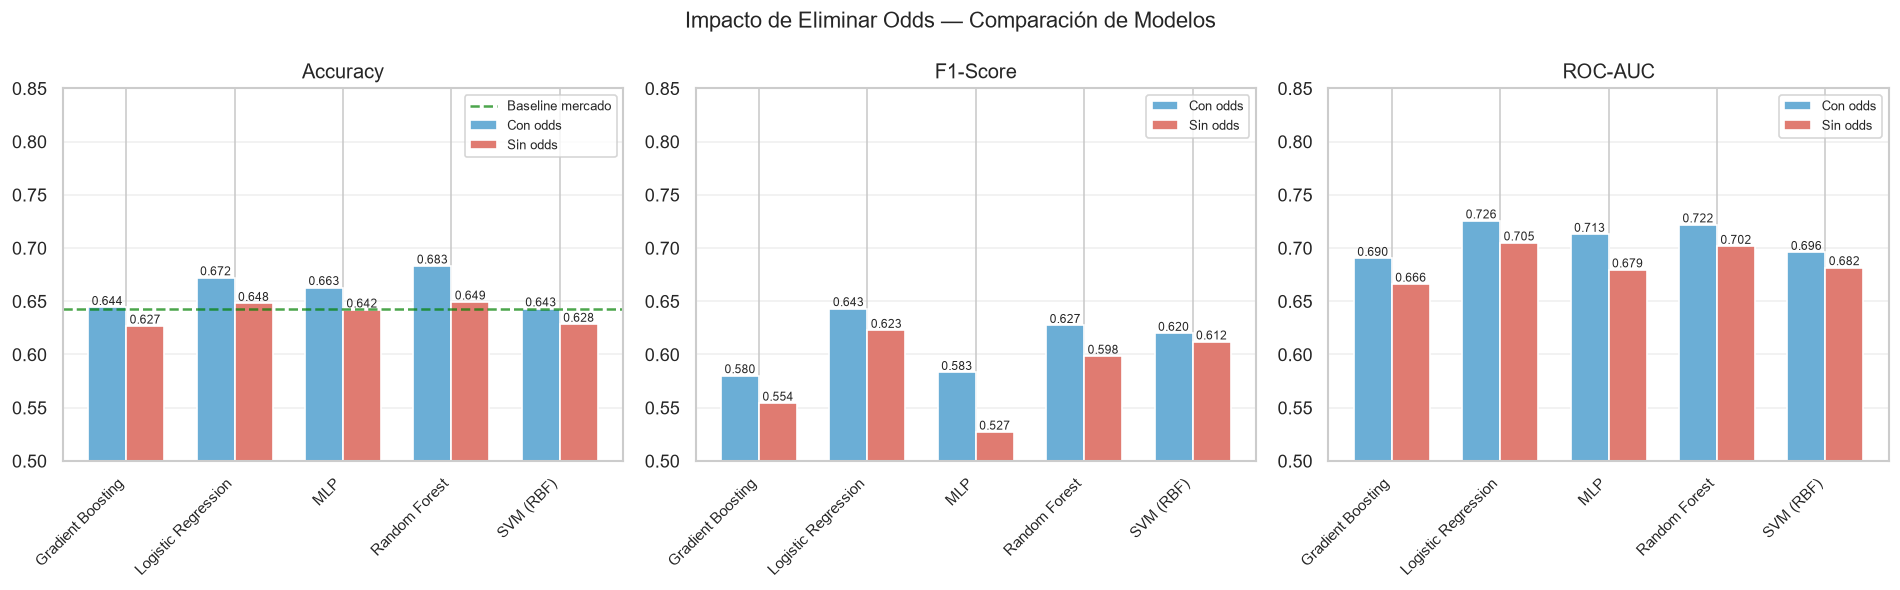

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics_to_plot = ['accuracy', 'f1_score', 'roc_auc']
metric_labels = ['Accuracy', 'F1-Score', 'ROC-AUC']

x = np.arange(len(comparison.index))
width = 0.35

for ax, metric, label in zip(axes, metrics_to_plot, metric_labels):
    # Barras con odds
    bars1 = ax.bar(x - width/2, comparison[f'{metric}_con'], width,
                   label='Con odds', color='#6baed6', edgecolor='white')
    
    # Barras sin odds
    bars2 = ax.bar(x + width/2, comparison[f'{metric}_sin'], width,
                   label='Sin odds', color='#e07b71', edgecolor='white')
    
    # Línea de baseline del mercado
    if metric == 'accuracy':
        ax.axhline(BASELINE_ACC, color='green', linestyle='--', linewidth=1.5,
                   alpha=0.7, label='Baseline mercado')
    
    ax.set_xticks(x)
    ax.set_xticklabels(comparison.index, rotation=45, ha='right', fontsize=9)
    ax.set_title(label, fontsize=12)
    ax.set_ylim(0.5, 0.85)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, axis='y')
    
    # Agregar valores
    for bar in bars1:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
               f'{height:.3f}', ha='center', va='bottom', fontsize=7)
    for bar in bars2:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
               f'{height:.3f}', ha='center', va='bottom', fontsize=7)

plt.suptitle('Impacto de Eliminar Odds — Comparación de Modelos', fontsize=13)
plt.tight_layout()
plt.savefig('Imagenes/sin_odds/comparacion_odds.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 6. Análisis por Fold

### ¿Mejora o empeora con más datos?

Si la brecha entre "con odds" y "sin odds" **se reduce** con más datos de entrenamiento, significa que el modelo está aprendiendo patrones propios.

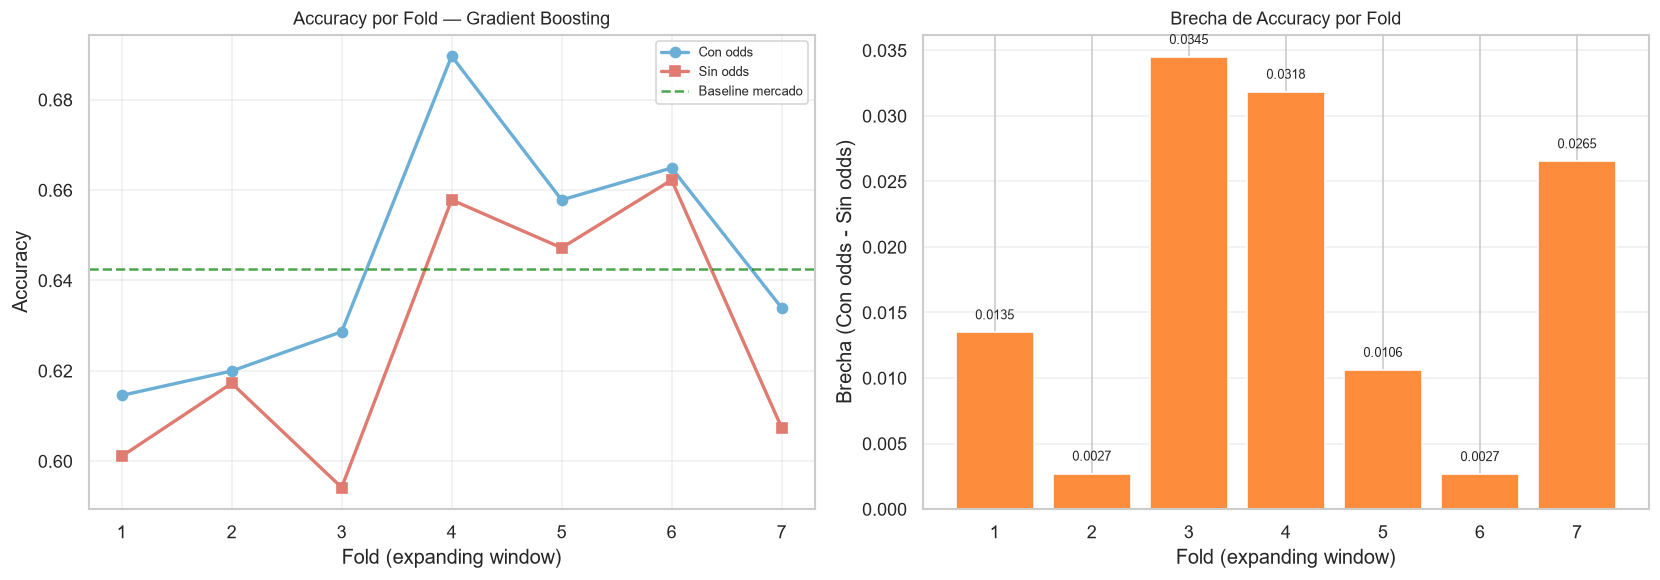

In [10]:
# Evolución de la brecha por fold
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Para Gradient Boosting (mejor modelo)
gb_with = df_with[df_with['model'] == 'Gradient Boosting']
gb_without = df_without[df_without['model'] == 'Gradient Boosting']

# Accuracy por fold
axes[0].plot(gb_with['fold'], gb_with['accuracy'], marker='o', 
             color='#6baed6', linewidth=2, label='Con odds')
axes[0].plot(gb_without['fold'], gb_without['accuracy'], marker='s', 
             color='#e07b71', linewidth=2, label='Sin odds')
axes[0].axhline(BASELINE_ACC, color='green', linestyle='--', alpha=0.7, label='Baseline mercado')
axes[0].set_xlabel('Fold (expanding window)')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy por Fold — Gradient Boosting', fontsize=11)
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

# Brecha (diferencia) por fold
brecha = gb_with['accuracy'].values - gb_without['accuracy'].values
axes[1].bar(gb_with['fold'], brecha, color='#fd8d3c', edgecolor='white')
axes[1].axhline(0, color='black', linestyle='-', linewidth=0.5)
axes[1].set_xlabel('Fold (expanding window)')
axes[1].set_ylabel('Brecha (Con odds - Sin odds)')
axes[1].set_title('Brecha de Accuracy por Fold', fontsize=11)
axes[1].grid(True, alpha=0.3, axis='y')

# Agregar valores
for i, (f, b) in enumerate(zip(gb_with['fold'], brecha)):
    axes[1].text(f, b + 0.001 if b >= 0 else b - 0.003, f'{b:.4f}', 
                ha='center', fontsize=8)

plt.tight_layout()
plt.savefig('Imagenes/sin_odds/brecha_por_fold.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 7. ¿Qué Features Compensan la Ausencia de Odds?

### ¿Qué aprende el modelo sin odds?

Si el modelo mantiene rendimiento sin odds, significa que hay **otras features** que capturan información similar.

 TOP 15 FEATURES SIN ODDS:
    1. 0.1056  home_season_gd
    2. 0.0701  diff_player_quality
    3. 0.0658  away_roll_shots
    4. 0.0651  diff_team_int_per90
    5. 0.0545  home_roll_shots
    6. 0.0466  diff_squad_age
    7. 0.0458  diff_avg_on_off
    8. 0.0417  away_season_goals_against
    9. 0.0417  away_roll_corners
   10. 0.0416  diff_gk_cs_pct
   11. 0.0373  home_roll_corners
   12. 0.0361  diff_team_discipline_per90
   13. 0.0350  diff_team_tkl_per90
   14. 0.0343  home_season_goals_against
   15. 0.0327  h2h_away_goals_avg


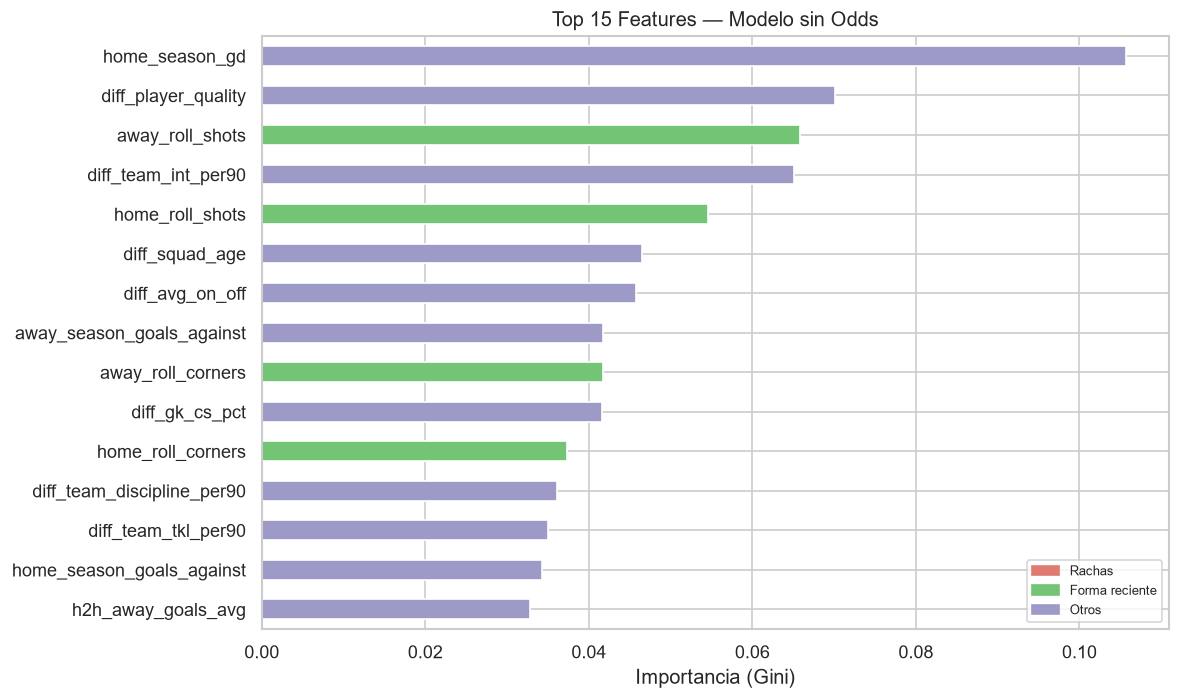

In [11]:
from sklearn.inspection import permutation_importance

# Entrenar Gradient Boosting sin odds
X_train_wo = X_without_odds.iloc[folds[-1][0]]  # Último fold
y_train = y.iloc[folds[-1][0]]

gb_wo = GradientBoostingClassifier(
    n_estimators=400, learning_rate=0.05, max_depth=4,
    subsample=0.8, random_state=42
)
gb_wo.fit(X_train_wo, y_train)

# Importancia de features
importance_wo = pd.Series(gb_wo.feature_importances_, index=X_without_odds.columns)
importance_wo = importance_wo.sort_values(ascending=False)

print(' TOP 15 FEATURES SIN ODDS:')
print('='*60)
for i, (feat, imp) in enumerate(importance_wo.head(15).items(), 1):
    print(f'   {i:2d}. {imp:.4f}  {feat}')

# Visualizar
fig, ax = plt.subplots(figsize=(10, 6))
top15 = importance_wo.head(15).sort_values()

colors = ['#e07b71' if 'streak' in f else 
          '#74c476' if 'roll' in f else
          '#9e9ac8' for f in top15.index]

top15.plot(kind='barh', color=colors, edgecolor='white', ax=ax)
ax.set_title('Top 15 Features — Modelo sin Odds', fontsize=12)
ax.set_xlabel('Importancia (Gini)')

from matplotlib.patches import Patch
legend_elements = [
    Patch(color='#e07b71', label='Rachas'),
    Patch(color='#74c476', label='Forma reciente'),
    Patch(color='#9e9ac8', label='Otros')
]
ax.legend(handles=legend_elements, fontsize=8)

plt.tight_layout()
plt.savefig('Imagenes/sin_odds/features_sin_odds.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 8. Conclusiones

### ¿Qué nos dice este análisis?

1. **Si la brecha es grande** (>3 puntos): El modelo depende del mercado
2. **Si la brecha es pequeña** (<2 puntos): El modelo tiene valor propio
3. **Si la brecha se reduce con folds**: El modelo aprende con más datos

### Implicaciones para la tesis:

- Si el modelo depende de odds, **no es útil en producción** (las odds ya encapsuran esa info)
- Si tiene valor propio, **puede superar al mercado** en ciertas situaciones

In [12]:
print('='*70)
print(' RESUMEN — EVALUACIÓN SIN ODDS')
print('='*70)

# Calcular promedio de brecha
avg_brecha_acc = comparison['accuracy_diff'].mean()
avg_brecha_f1 = comparison['f1_score_diff'].mean()
avg_brecha_auc = comparison['roc_auc_diff'].mean()

print(f'\n Brecha promedio (Con odds - Sin odds):')
print(f'   Accuracy: {avg_brecha_acc:+.4f} ({avg_brecha_acc/BASELINE_ACC*100:+.2f}% relativo)')
print(f'   F1-Score: {avg_brecha_f1:+.4f}')
print(f'   ROC-AUC:  {avg_brecha_auc:+.4f}')

print(f'\n Interpretación:')
if abs(avg_brecha_acc) < 0.02:
    print('   ✓ La brecha es PEQUEÑA (<2 puntos)')
    print('   ✓ El modelo tiene valor predictivo PROPIO')
    print('   ✓ Puede ser útil en producción sin depender del mercado')
elif abs(avg_brecha_acc) < 0.05:
    print('   ⚠ La brecha es MODERADA (2-5 puntos)')
    print('   ⚠ El modelo tiene algo de dependencia del mercado')
    print('   ⚠ Puede ser útil pero con precaución')
else:
    print('   ✗ La brecha es GRANDE (>5 puntos)')
    print('   ✗ El modelo depende fuertemente del mercado')
    print('   ✗ No recomendado para producción')

print('\n' + '='*70)
print(' Guardando resultados...')

# Guardar comparación
comparison.to_csv('resultados/comparacion_odds.csv')
print('   Comparación: resultados/comparacion_odds.csv')

# Guardar resultados detallados
df_with.to_csv('resultados/resultados_con_odds.csv', index=False)
df_without.to_csv('resultados/resultados_sin_odds.csv', index=False)
print('   Detalles: resultados/resultados_con_odds.csv')
print('             resultados/resultados_sin_odds.csv')
print('='*70)

 RESUMEN — EVALUACIÓN SIN ODDS

 Brecha promedio (Con odds - Sin odds):
   Accuracy: +0.0222 (+3.45% relativo)
   F1-Score: +0.0278
   ROC-AUC:  +0.0226

 Interpretación:
   ⚠ La brecha es MODERADA (2-5 puntos)
   ⚠ El modelo tiene algo de dependencia del mercado
   ⚠ Puede ser útil pero con precaución

 Guardando resultados...
   Comparación: resultados/comparacion_odds.csv
   Detalles: resultados/resultados_con_odds.csv
             resultados/resultados_sin_odds.csv
